In [ ]:
# ==========================================================
# NOTEBOOK 5
# TRANSIT DETECTION USING WEIGHTED BOX LEAST SQUARES (BLS)
# ==========================================================

import os
import csv
import shutil
import warnings
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm import tqdm
from astropy.timeseries import BoxLeastSquares

warnings.filterwarnings("ignore")

In [ ]:
# ==========================================================
# DATASET PATHS
# ==========================================================

INPUT_FOLDER = "/content/drive/MyDrive/Exoplanet_Dataset/05_Preprocessed_LightCurves"

RESULT_FOLDER = "/content/drive/MyDrive/Exoplanet_Dataset/06_BLS_Results"

PLOT_FOLDER = "/content/drive/MyDrive/Exoplanet_Dataset/06_BLS_Plots"

LOG_FOLDER = "/content/drive/MyDrive/Exoplanet_Dataset/11_Logs"

SUMMARY_FILE = os.path.join(
    RESULT_FOLDER,
    "BLS_Summary.csv"
)

LOG_FILE = os.path.join(
    LOG_FOLDER,
    "BLS_Log.csv"
)

In [ ]:
# ==========================================================
# BLS SEARCH PARAMETERS
# ==========================================================

MIN_PERIOD = 0.5
MAX_PERIOD = 15.0

MIN_DURATION = 0.03
MAX_DURATION = 0.25

NUMBER_OF_PERIODS = 6000

NUMBER_OF_DURATIONS = 50

MIN_POINTS = 100

In [ ]:
# ==========================================================
# PERIOD & DURATION GRID
# ==========================================================

PERIOD_GRID = np.linspace(

    MIN_PERIOD,

    MAX_PERIOD,

    NUMBER_OF_PERIODS

)

DURATIONS = np.linspace(

    MIN_DURATION,

    MAX_DURATION,

    NUMBER_OF_DURATIONS

)

print()

print("Periods :", len(PERIOD_GRID))

print("Durations :", len(DURATIONS))


Periods : 6000
Durations : 50


In [ ]:
# ==========================================================
# CREATE OUTPUT FILES
# ==========================================================

if not os.path.exists(SUMMARY_FILE):

    with open(SUMMARY_FILE, "w", newline="") as file:

        writer = csv.writer(file)

        writer.writerow([

            "TIC_ID",

            "Label",

            "Number_of_Sectors",

            "Best_Sector",

            "Detected_Period",

            "Detected_Duration",

            "Detected_Epoch",

            "BLS_Depth",

            "BLS_Power",

            "Peak_Significance"

        ])

if not os.path.exists(LOG_FILE):

    with open(LOG_FILE, "w", newline="") as file:

        writer = csv.writer(file)

        writer.writerow([

            "TIC_ID",

            "Status",

            "Runtime_Seconds"

        ])

In [ ]:
# ==========================================================
# RESUME SUPPORT
# ==========================================================

if os.path.exists(SUMMARY_FILE):

    processed_df = pd.read_csv(SUMMARY_FILE)

    processed_tics = set(

        processed_df["TIC_ID"].astype(int)

    )

else:

    processed_tics = set()

print()

print("Already Processed :", len(processed_tics))


Already Processed : 636


In [ ]:
# ==========================================================
# LOAD DATASET
# ==========================================================

FILES = sorted([

    file

    for file in os.listdir(INPUT_FOLDER)

    if file.endswith(".csv")

])

print()

print("="*60)

print("Notebook 5 Ready")

print("="*60)

print()

print("Total Stars :", len(FILES))

print("Already Processed :", len(processed_tics))

print("Remaining :", len(FILES)-len(processed_tics))


Notebook 5 Ready

Total Stars : 1172
Already Processed : 636
Remaining : 536


In [ ]:
# ==========================================================
# RUN WEIGHTED BOX LEAST SQUARES
# ==========================================================

def run_bls(sector_df):

    # ------------------------------------------------------
    # Extract Arrays
    # ------------------------------------------------------

    time = sector_df["Time"].to_numpy(dtype=np.float64)

    flux = sector_df["Normalized_Flux"].to_numpy(dtype=np.float64)

    flux_error = sector_df["Normalized_Flux_Error"].to_numpy(dtype=np.float64)

    # ------------------------------------------------------
    # Remove Invalid Values
    # ------------------------------------------------------

    valid = (

        np.isfinite(time)

        &

        np.isfinite(flux)

        &

        np.isfinite(flux_error)

    )

    time = time[valid]

    flux = flux[valid]

    flux_error = flux_error[valid]

    # ------------------------------------------------------
    # Skip Very Small Light Curves
    # ------------------------------------------------------

    if len(time) < MIN_POINTS:

        return None

    # ------------------------------------------------------
    # Weighted BLS
    # ------------------------------------------------------

    bls = BoxLeastSquares(

        t=time,

        y=flux,

        dy=flux_error

    )

    result = bls.power(

        PERIOD_GRID,

        DURATIONS

    )

    # ------------------------------------------------------
    # Best Detection
    # ------------------------------------------------------

    best = np.argmax(result.power)

    power = result.power

    std = np.std(power)

    if std == 0:

        peak = 0.0

    else:

        peak = (

            power[best]

            -

            np.mean(power)

        ) / std

    return {

        "Detected_Period":

            float(result.period[best]),

        "Detected_Duration":

            float(result.duration[best]),

        "Detected_Epoch":

            float(result.transit_time[best]),

        "BLS_Depth":

            float(result.depth[best]),

        "BLS_Power":

            float(power[best]),

        "Peak_Significance":

            float(peak)

    }

In [ ]:
# ==========================================================
# PROCESS ONE STAR
# ==========================================================

def process_star(file_name):

    file_path = os.path.join(

        INPUT_FOLDER,

        file_name

    )

    df = pd.read_csv(file_path)

    tic_id = int(df["TIC_ID"].iloc[0])

    label = df["Label"].iloc[0]

    sectors = sorted(

        df["Sector"].unique()

    )

    best_power = -np.inf

    best_sector = None

    best_output = None

    # ------------------------------------------------------

    for sector in sectors:

        sector_df = df[

            df["Sector"] == sector

        ]

        output = run_bls(

            sector_df

        )

        if output is None:

            continue

        if output["BLS_Power"] > best_power:

            best_power = output["BLS_Power"]

            best_sector = int(sector)

            best_output = output

    if best_output is None:

        return None

    return {

        "TIC_ID": tic_id,

        "Label": label,

        "Number_of_Sectors": len(sectors),

        "Best_Sector": best_sector,

        **best_output

    }

In [ ]:
# ==========================================================
# PROCESS COMPLETE DATASET
# ==========================================================

print("=" * 60)
print("BLS DETECTION STARTED")
print("=" * 60)

successful = 0
failed = 0

start_all = time.perf_counter()

for file in tqdm(FILES):

    try:

        # --------------------------------------------------
        # Read TIC ID
        # --------------------------------------------------

        temp = pd.read_csv(

            os.path.join(
                INPUT_FOLDER,
                file
            ),

            usecols=["TIC_ID"]

        )

        tic = int(temp.iloc[0, 0])

        # --------------------------------------------------
        # Resume Support
        # --------------------------------------------------

        if tic in processed_tics:

            continue

        # --------------------------------------------------
        # Process Star
        # --------------------------------------------------

        start_star = time.perf_counter()

        summary = process_star(file)

        runtime = time.perf_counter() - start_star

        if summary is None:

            failed += 1

            with open(LOG_FILE, "a", newline="") as log:

                writer = csv.writer(log)

                writer.writerow([

                    tic,

                    "FAILED",

                    round(runtime, 2)

                ])

            continue

        # --------------------------------------------------
        # Save Result Immediately
        # --------------------------------------------------

        with open(SUMMARY_FILE, "a", newline="") as csvfile:

            writer = csv.writer(csvfile)

            writer.writerow([

                summary["TIC_ID"],

                summary["Label"],

                summary["Number_of_Sectors"],

                summary["Best_Sector"],

                summary["Detected_Period"],

                summary["Detected_Duration"],

                summary["Detected_Epoch"],

                summary["BLS_Depth"],

                summary["BLS_Power"],

                summary["Peak_Significance"]

            ])

            csvfile.flush()

            os.fsync(csvfile.fileno())

        # --------------------------------------------------
        # Save Log
        # --------------------------------------------------

        with open(LOG_FILE, "a", newline="") as logfile:

            writer = csv.writer(logfile)

            writer.writerow([

                summary["TIC_ID"],

                "SUCCESS",

                round(runtime, 2)

            ])

            logfile.flush()

            os.fsync(logfile.fileno())

        processed_tics.add(summary["TIC_ID"])

        successful += 1

    except Exception as error:

        failed += 1

        print(f"\nFailed : {file}")

        print(error)

end_all = time.perf_counter()

BLS DETECTION STARTED


100%|██████████| 1172/1172 [7:00:29<00:00, 21.53s/it]


In [ ]:
# ==========================================================
# FINAL SUMMARY
# ==========================================================

print()

print("=" * 60)
print("BLS DETECTION COMPLETE")
print("=" * 60)

print()

print("New Stars Processed :", successful)

print("Failed :", failed)

print()

print("Total Runtime (minutes) :",

      round(

          (end_all - start_all) / 60,

          2

      )
)

print()

print("Results Saved To")

print(SUMMARY_FILE)

print()

print("Log Saved To")

print(LOG_FILE)


BLS DETECTION COMPLETE

New Stars Processed : 536
Failed : 0

Total Runtime (minutes) : 420.49

Results Saved To
/content/drive/MyDrive/Exoplanet_Dataset/06_BLS_Results/BLS_Summary.csv

Log Saved To
/content/drive/MyDrive/Exoplanet_Dataset/11_Logs/BLS_Log.csv


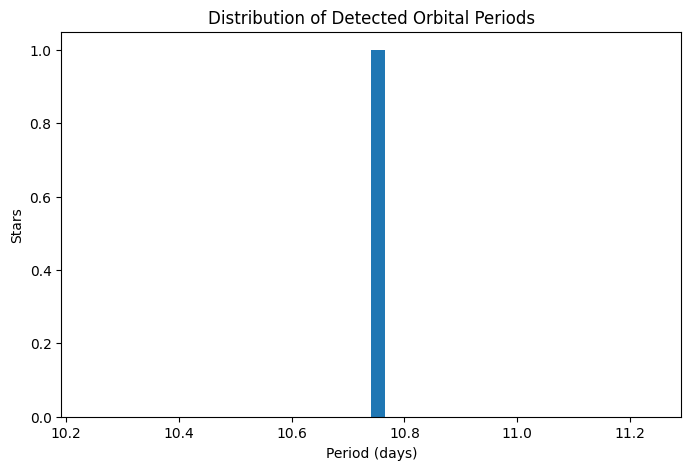

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(summary["Detected_Period"], bins=40)

plt.xlabel("Period (days)")
plt.ylabel("Stars")
plt.title("Distribution of Detected Orbital Periods")

plt.show()

In [ ]:
print("Total stars :", len(FILES))
print("Processed :", len(summary))
print("Success % :", len(summary)/len(FILES)*100)

Total stars : 1172
Processed : 10
Success % : 0.8532423208191127


In [ ]:
import pandas as pd

summary = pd.read_csv(SUMMARY_FILE)

print(summary.shape)
print(summary.columns)
summary.head()

(1172, 10)
Index(['TIC_ID', 'Label', 'Number_of_Sectors', 'Best_Sector',
       'Detected_Period', 'Detected_Duration', 'Detected_Epoch', 'BLS_Depth',
       'BLS_Power', 'Peak_Significance'],
      dtype='object')


,TIC_ID,Label,Number_of_Sectors,Best_Sector,Detected_Period,Detected_Duration,Detected_Epoch,BLS_Depth,BLS_Power,Peak_Significance
0,100100829,EB,3,69,0.942324,0.075,3182.749443,0.007126,928.753290,13.017379
1,1001477809,False Positive,4,48,7.656943,0.168,2616.800708,0.001701,30.981110,5.724197
2,100389539,Planet,2,88,4.280297,0.114,3693.099793,0.005744,2436.410323,14.040970
3,10048801,EB,2,47,3.700200,0.141,2583.045512,0.000936,1420.646948,9.640867
4,100589632,False Positive,1,87,3.946741,0.066,3665.759898,0.001609,75.715224,10.109563


In [ ]:
print(len(summary))

1172


In [ ]:
import json

NOTEBOOK = "/content/drive/MyDrive/Exoplanet_Dataset/05_BLS_final.ipynb"

with open(NOTEBOOK, "r", encoding="utf-8") as f:
    nb = json.load(f)

for cell in nb["cells"]:
    if cell["cell_type"] != "code":
        continue

    code = "".join(cell["source"])

    if (
        "Detected_Epoch" in code
        or "process_star" in code
        or "best_epoch" in code
        or "transit_time" in code
    ):

        print("=" * 100)
        print(code)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Exoplanet_Dataset/05_BLS_final.ipynb'